In [15]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!rm -rf /usr/local/lib/python3*/dist-packages/cv2
!pip install -q --no-cache-dir opencv-python-headless==4.11.0.86
!wget -q -O /content/haarcascade_frontalface_default.xml https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml

In [1]:
import cv2
print(cv2.getVersionString())
det = cv2.CascadeClassifier("/content/haarcascade_frontalface_default.xml")
print("Detector cargado:", not det.empty())

4.11.0
Detector cargado: True


In [2]:
import os, shutil
from google.colab import drive

if os.path.ismount("/content/drive"):
    print("Drive ya estaba conectado")
else:
    if os.path.exists("/content/drive"):
        shutil.rmtree("/content/drive")
    drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"
for c in ["fotos_famosos", "fotos_estudiantes"]:
    ruta = os.path.join(BASE, c)
    if os.path.exists(ruta):
        print("OK", c, ":", sorted(os.listdir(ruta)))
    else:
        print("NO EXISTE:", ruta)

Drive ya estaba conectado
OK fotos_famosos : ['famoso_johnny_depp', 'famoso_leonardo_dicaprio', 'famoso_robert_downey_jr', 'famoso_taylor_swift', 'famoso_tom_cruise']
OK fotos_estudiantes : ['estudiante_jovani', 'estudiante_luis']


In [11]:
import os
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

BASE_EST = "/content/drive/MyDrive/fotos_estudiantes"
for est in sorted(os.listdir(BASE_EST)):
    carpeta = os.path.join(BASE_EST, est)
    print("Carpeta:", est)
    hay = False
    for raiz, dirs, archivos in os.walk(carpeta):
        for a in archivos:
            ruta = os.path.join(raiz, a)
            mb = round(os.path.getsize(ruta) / 1000000, 1)
            print("    ", ruta.replace(carpeta, ""), "-", mb, "MB")
            hay = True
    if not hay:
        print("    (vacia)")

Mounted at /content/drive
Carpeta: estudiante_jovani
     /WhatsApp Video 2026-11-24 at 7.56.20 PM.mp4 - 5.6 MB
Carpeta: estudiante_luis
     /WhatsApp Video 2026-11-24 at 8.08.03 PM.mp4 - 5.6 MB
     /WhatsApp Video 2026-11-24 at 8.08.08 PM.mp4 - 4.3 MB


In [3]:
import os, shutil, subprocess, cv2, numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

ORIGENES = ["/content/drive/MyDrive/fotos_famosos",
            "/content/drive/MyDrive/fotos_estudiantes"]
RUTA_DATASET = "/content/drive/MyDrive/dataset_cnn"
TEMP = "/content/frames_tmp"
OBJETIVO = 80
EXT_IMG = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
EXT_VID = (".mp4", ".mov", ".3gp", ".avi", ".mkv", ".webm", ".m4v")

for carpeta in [RUTA_DATASET, TEMP]:
    if os.path.exists(carpeta):
        shutil.rmtree(carpeta)
    os.makedirs(carpeta)

face_cascade = cv2.CascadeClassifier("/content/haarcascade_frontalface_default.xml")
if face_cascade.empty():
    raise RuntimeError("No se cargo el detector. Corran primero la Celda 0.")

aumentador = ImageDataGenerator(
    rotation_range=15, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.15, horizontal_flip=True,
    brightness_range=[0.7, 1.3], fill_mode="nearest")


def recortar(img):
    giros = [None, cv2.ROTATE_90_CLOCKWISE, cv2.ROTATE_90_COUNTERCLOCKWISE]
    for giro in giros:
        if giro is None:
            im = img
        else:
            im = cv2.rotate(img, giro)
        gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        r = face_cascade.detectMultiScale(
            gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        if len(r):
            x, y, w, h = max(r, key=lambda b: b[2] * b[3])
            mx = int(w * 0.08)
            my = int(h * 0.08)
            cara = im[y + my:y + h - my, x + mx:x + w - mx]
            return cv2.resize(cara, (224, 224))
    return None


def fotos_de_video(ruta, carpeta_salida, n):
    patron = os.path.join(carpeta_salida, f"v{n}_%04d.jpg")
    subprocess.run(["ffmpeg", "-loglevel", "error", "-y",
                    "-i", ruta, "-vf", "fps=3", patron])
    fotos = [a for a in os.listdir(carpeta_salida) if a.startswith(f"v{n}_")]
    return [os.path.join(carpeta_salida, a) for a in sorted(fotos)]


for origen in ORIGENES:
    if not os.path.exists(origen):
        print("No existe:", origen)
        continue
    for persona in sorted(os.listdir(origen)):
        carpeta = os.path.join(origen, persona)
        if not os.path.isdir(carpeta):
            continue
        tmp = os.path.join(TEMP, persona)
        os.makedirs(tmp)
        caras = []
        ignorados = []
        n_vid = 0

        for raiz, dirs, archivos in os.walk(carpeta):
            for archivo in sorted(archivos):
                ruta = os.path.join(raiz, archivo)
                nombre = archivo.lower()
                if nombre.endswith(EXT_IMG):
                    img = cv2.imread(ruta)
                    c = None
                    if img is not None:
                        c = recortar(img)
                    if c is not None:
                        caras.append(c)
                    else:
                        ignorados.append(archivo)
                elif nombre.endswith(EXT_VID):
                    n_vid += 1
                    antes = len(caras)
                    for fr in fotos_de_video(ruta, tmp, n_vid):
                        img = cv2.imread(fr)
                        if img is not None:
                            c = recortar(img)
                            if c is not None:
                                caras.append(c)
                    print("   Video", archivo, ":", len(caras) - antes, "caras")
                else:
                    ignorados.append(archivo)

        if len(caras) == 0:
            print("PROBLEMA:", persona, "no tiene ninguna cara detectada")
            continue

        if max(len(caras), OBJETIVO) != OBJETIVO:
            idx = np.linspace(0, len(caras) - 1, OBJETIVO).astype(int)
            caras = [caras[j] for j in idx]

        destino = os.path.join(RUTA_DATASET, persona)
        os.makedirs(destino)
        i = 0
        for c in caras:
            cv2.imwrite(os.path.join(destino, f"{persona}_{i:03d}.jpg"), c)
            i += 1
        while i != OBJETIVO:
            c = caras[i % len(caras)]
            lote = aumentador.flow(np.expand_dims(c, 0), batch_size=1)
            aug = next(lote)[0].astype(np.uint8)
            cv2.imwrite(os.path.join(destino, f"{persona}_{i:03d}.jpg"), aug)
            i += 1

        print("OK", persona, ":", len(caras), "caras reales, total", i, "imagenes")
        if ignorados:
            print("   Sin cara o formato no valido:", ignorados[:5])

print()
print("Clases listas:", sorted(os.listdir(RUTA_DATASET)))

OK famoso_johnny_depp : 5 caras reales, total 80 imagenes
OK famoso_leonardo_dicaprio : 5 caras reales, total 80 imagenes
OK famoso_robert_downey_jr : 5 caras reales, total 80 imagenes
OK famoso_taylor_swift : 4 caras reales, total 80 imagenes
   Sin cara o formato no valido: ['91a371f5d3b3bf1b201b459fe1286520.jpg']
OK famoso_tom_cruise : 4 caras reales, total 80 imagenes
   Sin cara o formato no valido: ['640x971-d6e2dba1-55d7-11e6-969a-3d485c95dc23ocio-tom-cruise-anos-1993-11847027-1-esl-es-1993-jpg.avif']
   Video WhatsApp Video 2026-11-24 at 7.56.20 PM.mp4 : 69 caras
OK estudiante_jovani : 69 caras reales, total 80 imagenes
   Video WhatsApp Video 2026-11-24 at 8.08.03 PM.mp4 : 53 caras
   Video WhatsApp Video 2026-11-24 at 8.08.08 PM.mp4 : 39 caras
OK estudiante_luis : 80 caras reales, total 80 imagenes

Clases listas: ['estudiante_jovani', 'estudiante_luis', 'famoso_johnny_depp', 'famoso_leonardo_dicaprio', 'famoso_robert_downey_jr', 'famoso_taylor_swift', 'famoso_tom_cruise']


In [ ]:
import os, shutil, subprocess, cv2, numpy as np

BASE_EST = "/content/drive/MyDrive/fotos_estudiantes"
TEMP = "/content/frames_tmp"

for est in sorted(os.listdir(BASE_EST)):
    carpeta = os.path.join(BASE_EST, est)
    if not os.path.isdir(carpeta):
        continue
    print("Estudiante:", est)

    salida = os.path.join(TEMP, est)
    if os.path.exists(salida):
        shutil.rmtree(salida)
    os.makedirs(salida)

    n = 0
    for raiz, dirs, archivos in os.walk(carpeta):
        for archivo in sorted(archivos):
            if not archivo.lower().endswith(EXT_VID):
                continue
            n += 1
            patron = os.path.join(salida, f"v{n}_%04d.jpg")
            subprocess.run(["ffmpeg", "-loglevel", "error", "-y",
                            "-i", os.path.join(raiz, archivo),
                            "-vf", "fps=3", patron])
            print("   Video", n, ":", archivo)

    frames = sorted(os.listdir(salida))
    print("   Fotos sacadas de los videos:", len(frames))

    caras = []
    for fr in frames:
        img = cv2.imread(os.path.join(salida, fr))
        if img is not None:
            c = recortar(img)
            if c is not None:
                caras.append(c)
    print("   Caras detectadas:", len(caras))

    if len(caras) == 0:
        print("   PROBLEMA: no se detectaron caras en los videos")
        continue

    if max(len(caras), OBJETIVO) != OBJETIVO:
        idx = np.linspace(0, len(caras) - 1, OBJETIVO).astype(int)
        caras = [caras[j] for j in idx]

    destino = os.path.join(RUTA_DATASET, est)
    if os.path.exists(destino):
        shutil.rmtree(destino)
    os.makedirs(destino)

    i = 0
    for c in caras:
        cv2.imwrite(os.path.join(destino, f"{est}_{i:03d}.jpg"), c)
        i += 1
    while i != OBJETIVO:
        c = caras[i % len(caras)]
        lote = aumentador.flow(np.expand_dims(c, 0), batch_size=1)
        aug = next(lote)[0].astype(np.uint8)
        cv2.imwrite(os.path.join(destino, f"{est}_{i:03d}.jpg"), aug)
        i += 1
    print("   OK", est, ":", len(caras), "caras reales, total", i, "imagenes")

print()
print("Clases listas:", sorted(os.listdir(RUTA_DATASET)))

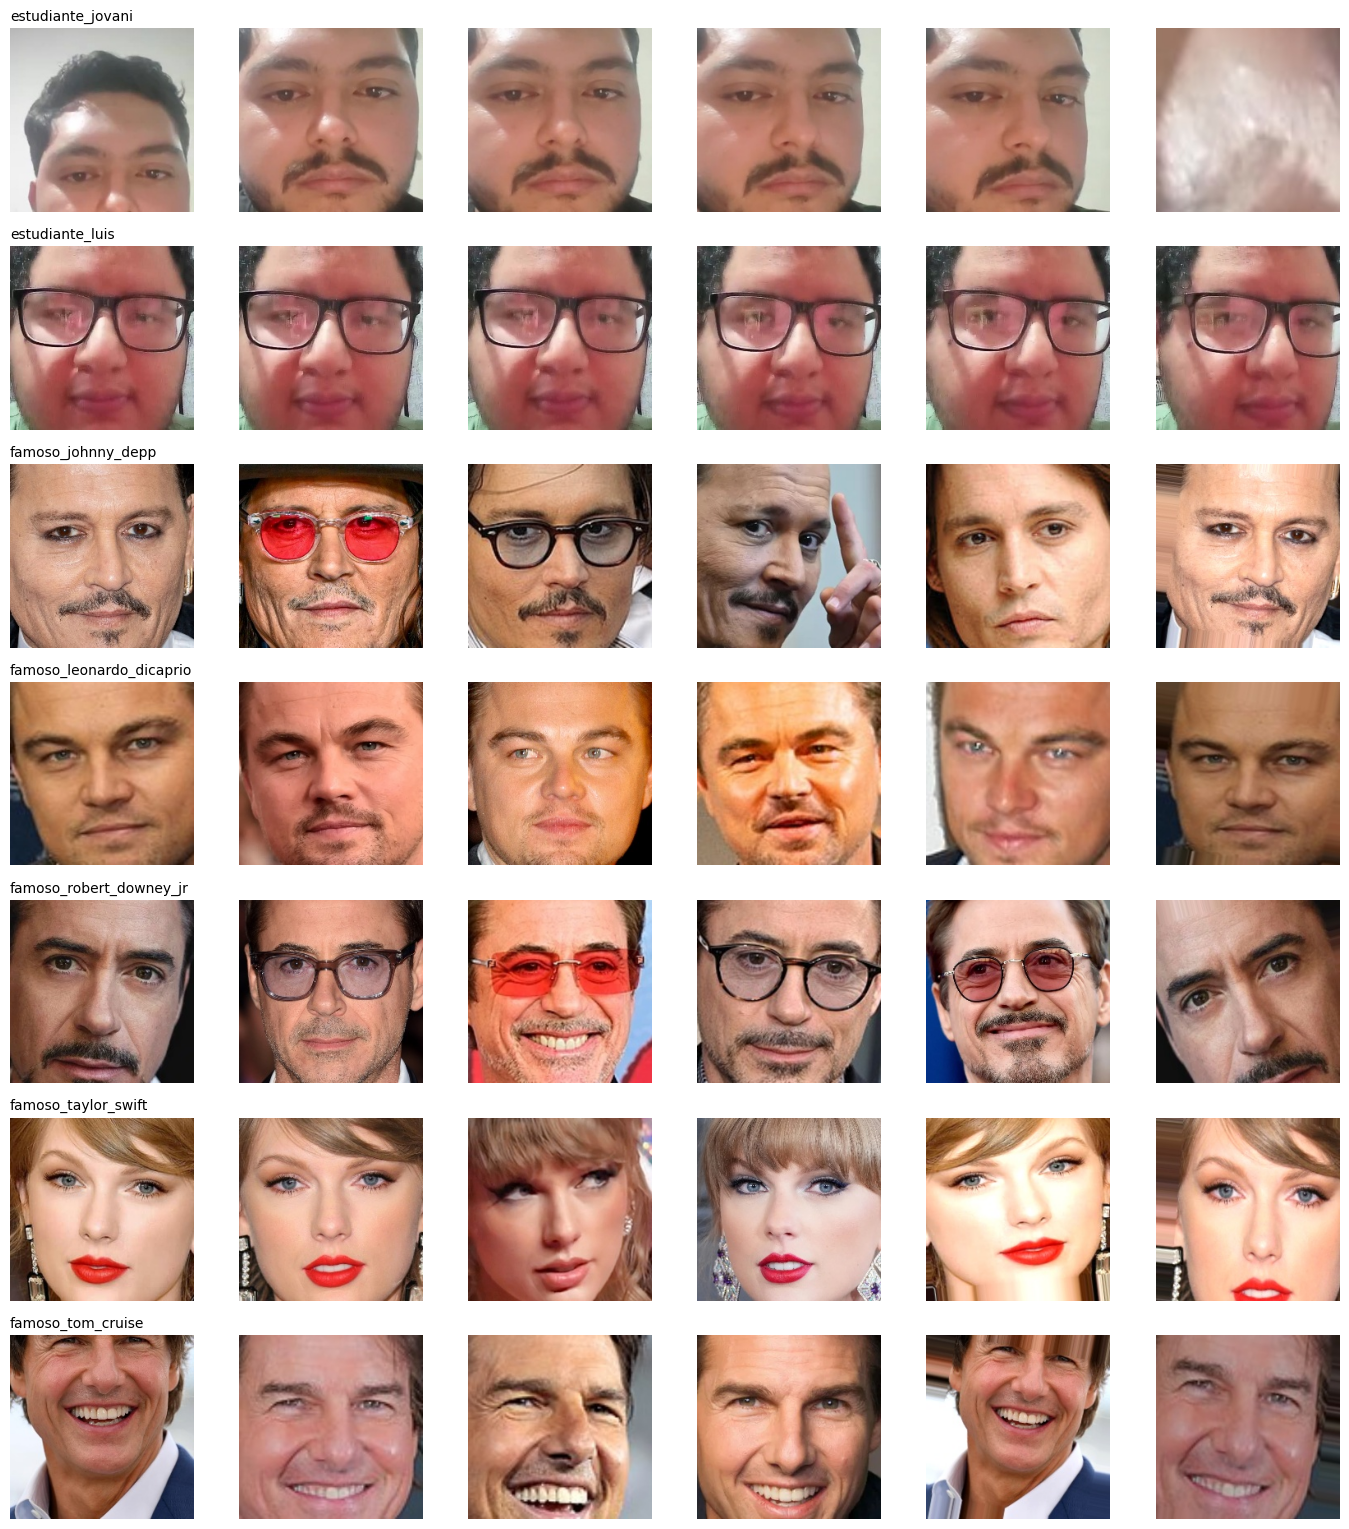

In [4]:
import matplotlib.pyplot as plt

clases_ds = sorted(os.listdir(RUTA_DATASET))
plt.figure(figsize=(14, 2.2 * len(clases_ds)))
k = 1
for clase in clases_ds:
    archivos = sorted(os.listdir(os.path.join(RUTA_DATASET, clase)))[:6]
    for a in archivos:
        img = cv2.cvtColor(cv2.imread(os.path.join(RUTA_DATASET, clase, a)), cv2.COLOR_BGR2RGB)
        plt.subplot(len(clases_ds), 6, k)
        plt.imshow(img)
        plt.axis("off")
        if k % 6 == 1:
            plt.title(clase, loc="left", fontsize=10)
        k += 1
plt.tight_layout()
plt.show()

Found 448 images belonging to 7 classes.
Found 112 images belonging to 7 classes.
Clases: {0: 'estudiante_jovani', 1: 'estudiante_luis', 2: 'famoso_johnny_depp', 3: 'famoso_leonardo_dicaprio', 4: 'famoso_robert_downey_jr', 5: 'famoso_taylor_swift', 6: 'famoso_tom_cruise'}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/25
28/28 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.6853 - loss: 0.9508 - val_accuracy: 0.7321 - val_loss: 0.6843
Epoch 2/25
28/28 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.9554 - loss: 0.1283 - val_accuracy: 0.8304 - val_loss: 0.4153
Epoch 3/25
28/28 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.9621 - loss: 0.0955 - val_accuracy: 0.9286 - val_loss: 0.2057
Epoch 4/25
28/28 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.9799 - loss: 0.0702 - val_accuracy: 0.9821 - val_loss: 0.1190
Epoch 5/25
28/28 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.9978 - loss: 0.0248 - val_accuracy: 0.9554 - val_loss: 0.1344
Epoch 6/25
28/28 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/ste

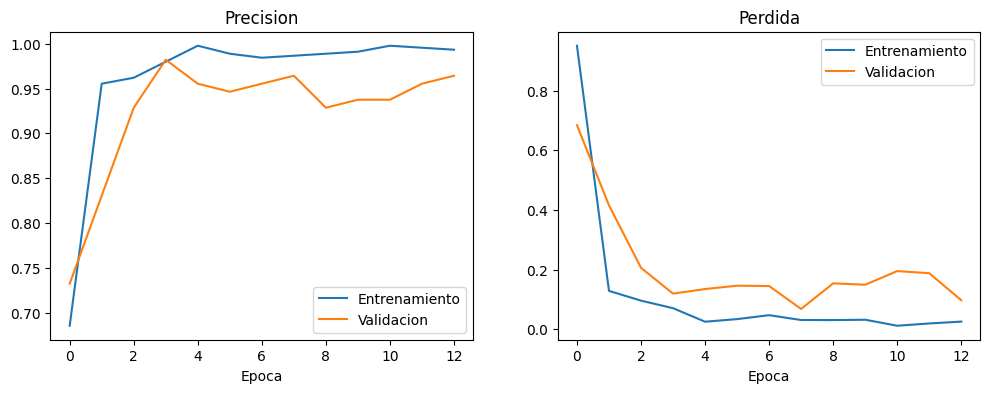

Mejor precision de validacion: 98.2 %


In [5]:
import json
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                             rotation_range=10, zoom_range=0.1, horizontal_flip=True,
                             brightness_range=[0.8, 1.2], validation_split=0.2)
train_gen = datagen.flow_from_directory(RUTA_DATASET, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
                                        class_mode="categorical", subset="training")
val_gen = datagen.flow_from_directory(RUTA_DATASET, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
                                      class_mode="categorical", subset="validation", shuffle=False)

clases = {v: k for k, v in train_gen.class_indices.items()}
with open("/content/drive/MyDrive/clases.json", "w") as f:
    json.dump(clases, f, ensure_ascii=False)
print("Clases:", clases)

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False
x = GlobalAveragePooling2D()(base.output)
x = BatchNormalization()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.4)(x)
salidas = Dense(len(clases), activation="softmax")(x)
modelo = Model(base.input, salidas)
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
               loss="categorical_crossentropy", metrics=["accuracy"])

callbacks = [EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
             ModelCheckpoint("/content/drive/MyDrive/modelo_facial.keras",
                             monitor="val_accuracy", save_best_only=True)]
hist = modelo.fit(train_gen, validation_data=val_gen, epochs=25, callbacks=callbacks)

plt.figure(figsize=(12, 4))
for i, m in enumerate(["accuracy", "loss"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(hist.history[m], label="Entrenamiento")
    plt.plot(hist.history["val_" + m], label="Validacion")
    plt.title("Precision" if m == "accuracy" else "Perdida")
    plt.xlabel("Epoca")
    plt.legend()
plt.show()
print("Mejor precision de validacion:", round(max(hist.history["val_accuracy"]) * 100, 1), "%")

In [7]:
from google.colab import files
files.download("/content/drive/MyDrive/modelo_facial.keras")
files.download("/content/drive/MyDrive/clases.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>